# 20. Ensemble subset: peak pressure and ground velocity against distance

A first pass over a handful of launches spanning 2016–2026, vehicles and pads, built entirely on
the shared code:

* the **launch catalog** (`event_catalog_workflow_v5`, reconciled sqlite) gives event times, pads and names;
* **`ksclib.catalog_events`** turns each catalog row into a `ksclib.Event`, choosing the network
  *era* from the event time (`ensemble.yaml`): 2016–2022 campaigns use the time-dependent StationXML
  `03_stationxml/KSC.xml` and the remastered SDS on `classdata`; the 2026 network uses the
  Centaur response files, infraBSU stage, SmartSolo PAZ and Gem response exactly as Artemis II;
* Gem overflow is masked with `flovopy.ingest.gem_overflow` where Gems were deployed (2026 era);
  peaks touching a masked interval are **lower bounds**.

Peaks follow Artemis II notebook 40: |p| high-passed at 0.5 Hz, vertical velocity at 1 Hz, in a
window from 30 s before to 300 s after the catalog time (catalog times are often only to the
minute); the noise reference is the 330 s before that. Distances are from the launch pad.

Run with the `flovopy_plus` environment. Products go to `ensemble.yaml: output` (override with
`ENSEMBLE_OUT_DIR`).

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PAPER_DIR = Path.cwd()
REPO_ROOT = PAPER_DIR.parent
# Use this repository's ksclib (catalog_events is new; the installed copy may predate it).
sys.path.insert(0, str(REPO_ROOT / "ksclib" / "src"))
from ksclib import catalog_events as ce

ens = ce.load_ensemble(PAPER_DIR / "ensemble.yaml")
OUT = ens.out_dir / "20_ensemble_subset"
OUT.mkdir(parents=True, exist_ok=True)
print("output:", OUT)
for era in ens.eras:
    print(f"{era.name:22s} {era.kind:10s} {era.start.date} - {era.end.date}")

output: /private/tmp/claude-502/-Users-glennthompson-Developer-KSCRocketSeismoHydrology--claude-worktrees-sharp-swartz-4b06f0/cfed1641-a00c-43f8-9a65-4d59cee65101/scratchpad/out/20_ensemble_subset
campaigns_2016_2022    stationxml 2016-01-01 - 2023-01-01
network_2026           centaur    2026-01-01 - 2027-01-01


## 1. Catalog

In [2]:
cat = ce.load_catalog(ens)
print(f"{len(cat)} events, {cat.event_time_utc.min()} - {cat.event_time_utc.max()}")
display(pd.crosstab(cat.year, cat.event_type, margins=True))
display(pd.crosstab(cat.vehicle, cat.pad_code))

203 events, 2016-02-05T13:38:00Z - 2026-04-01T22:35:12Z


event_type,aborted_launch,aircraft_sonic_boom,booster_landing,orbital_launch,pad_explosion,static_fire,All
year,,,,,,,
2016,1,0,0,18,1,5,25
2017,0,1,0,19,0,1,21
2018,0,0,0,20,0,0,20
2019,1,0,0,15,0,0,16
2020,0,0,0,31,0,0,31
2021,0,0,0,31,0,0,31
2022,0,0,1,57,0,0,58
2026,0,0,0,1,0,0,1
All,2,1,1,192,1,6,203


pad_code,L1011,LC37B,LC39A,LC39B,LC40,LC41,LC46,SLF
vehicle,,,,,,,,
084/B1048.5 F084,0,0,1,0,0,0,0,0
190/B1073.5 F190,0,0,0,0,1,0,0,0
191/B1058.15 F193,0,0,1,0,0,0,0,0
192/B1069.4 F189,0,0,1,0,0,0,0,0
193/B1067.8 F192,0,0,0,0,1,0,0,0
195/B1062.11 F194,0,0,0,0,1,0,0,0
Altas V 541,0,0,0,0,0,1,0,0
Atlas V,0,0,0,0,0,29,0,0
Delta IV,0,7,0,0,0,0,0,0


## 2. Subset

One or two launches per vehicle class and pad, from each network configuration:

| event | why |
|---|---|
| Falcon 9 SES-9 (2016, LC40) | first campaign: BCHH, FIRE, TANK (Trillium + 3 infraBSU each) |
| Delta IV Heavy NROL-37 (2016, LC37B) | largest ULA vehicle, BCHH only |
| Falcon Heavy demo (2018, LC39A) | temporary deployment DVEL1/DVEL2/RBLAB for this launch |
| Atlas V AEHF-4 (2018, LC41) | beach geophone array BHP2–8 |
| Ascent Abort-2 (2019, LC46) | short, low-altitude flight from the southern pad |
| Atlas V Lucy (2021, LC41) | RB166/RB268/RB383 at RBLAB (Robert Brown lab), named after their Centaur serials |
| SLS Artemis I (2022, LC39B) | S39A1–3, BCHH, Raspberry Shakes; pairs with Artemis II |
| SLS Artemis II (2026, LC39B) | 2026 network (Centaur, Gem, SmartSolo), not yet in the catalog |

In [3]:
SUBSET = [
    "ksc-4d8977e0556d",   # Falcon 9 SES-9
    "ksc-84ff2d3935e5",   # Delta IV Heavy NROL-37
    "ksc-63e156ef62c2",   # Falcon Heavy demo
    "ksc-0eaa94e13c72",   # Atlas V AEHF-4
    "ksc-da8b52e60732",   # Ascent Abort-2
    "ksc-38ab2b5b43b8",   # Atlas V Lucy
    "ksc-893bace1e8c8",   # SLS Artemis I
    "artemis2-20260401",  # SLS Artemis II
]
sub = cat.set_index("event_id").loc[SUBSET].reset_index()
sub[["event_id", "event_time_utc", "event_time_precision", "event_type", "vehicle", "pad_code", "name", "era"]]

,event_id,event_time_utc,event_time_precision,event_type,vehicle,pad_code,name,era
0,ksc-4d8977e0556d,2016-03-04T23:35:00Z,minute,orbital_launch,Falcon 9,LC40,Falcon 9 1.2|F9-22 SES-9,campaigns_2016_2022
1,ksc-84ff2d3935e5,2016-06-11T17:51:00Z,minute,orbital_launch,Delta IV,LC37B,Delta IV Heavy|D374 NROL 37,campaigns_2016_2022
2,ksc-63e156ef62c2,2018-02-06T20:45:00Z,minute,orbital_launch,Falcon Heavy,LC39A,Falcon Heavy|Demo flight,campaigns_2016_2022
3,ksc-0eaa94e13c72,2018-10-17T04:15:00Z,minute,orbital_launch,Atlas V,LC41,Atlas V 551|AEHF-4,campaigns_2016_2022
4,ksc-da8b52e60732,2019-07-02T11:00:00Z,,aborted_launch,Orion Test Booster,LC46,Orion Test Booster | Ascent Abort-2,campaigns_2016_2022
5,ksc-38ab2b5b43b8,2021-10-16T09:34:00Z,minute,orbital_launch,Atlas V,LC41,Atlas V 401|AV-096 Lucy,campaigns_2016_2022
6,ksc-893bace1e8c8,2022-11-16T06:47:44Z,second,orbital_launch,SLS,LC39B,SLS Block 1 | Artemis 1,campaigns_2016_2022
7,artemis2-20260401,2026-04-01T22:35:12Z,second,orbital_launch,SLS,LC39B,SLS Block 1 | Artemis II,network_2026


## 3. Read, correct and measure each launch

For each event: build the `Event`, list the stations active at that time (with distance from the
pad), read raw counts from the era's archive, find Gem overflow intervals on the raw counts,
instrument-correct, and measure peaks. Failures are recorded, not fatal.

In [4]:
SIGNAL = (-ens.window.get("trim_before", 30), ens.window.get("trim_after", 300))
NOISE = (SIGNAL[0] - 300, SIGNAL[0])

peaks, status, events, streams = [], [], {}, {}
for _, row in sub.iterrows():
    eid = row.event_id
    try:
        ev = ce.event_from_row(row, ens)
        events[eid] = ev
        stations = ce.station_table(ev)
        raw = ce.read_raw(ev, starttime=ev.origin_time + NOISE[0] - 30, endtime=ev.origin_time + SIGNAL[1] + 30)
        clips = ce.clip_intervals(raw, ev)
        with warnings.catch_warnings(record=True) as w:
            warnings.simplefilter("always")
            st = ce.correct(raw, ev)
        dropped = sorted({str(x.message).split(":")[0] for x in w if "not corrected" in str(x.message) or "no response" in str(x.message)})
        streams[eid] = st
        pk = ce.peak_amplitudes(st, ev, stations, clips, signal=SIGNAL, noise=NOISE)
        pk["vehicle"], pk["year"], pk["time_precision"] = row.vehicle, row.year, row.event_time_precision
        peaks.append(pk)
        status.append(dict(event_id=eid, vehicle=row.vehicle, pad=ev.site_name, era=ev.raw["era"],
                           n_raw=len(raw), n_corrected=len(st), n_peaks=len(pk),
                           stations=" ".join(sorted({tr.stats.station for tr in raw})),
                           gem_overflow=sum(bool(v) for v in clips.values()),
                           dropped=" ".join(dropped), error=""))
    except Exception as exc:
        status.append(dict(event_id=eid, vehicle=row.vehicle, error=f"{type(exc).__name__}: {exc}"))
    print(f"{eid:20s} done")

status = pd.DataFrame(status)
peaks = pd.concat(peaks, ignore_index=True) if peaks else pd.DataFrame()
peaks.to_csv(OUT / "subset_peaks.csv", index=False)
status.to_csv(OUT / "subset_status.csv", index=False)
status

ksc-4d8977e0556d     done


ksc-84ff2d3935e5     done


ksc-63e156ef62c2     done


ksc-0eaa94e13c72     done


ksc-da8b52e60732     done


ksc-38ab2b5b43b8     done


ksc-893bace1e8c8     done


/Users/glennthompson/Developer/KSCRocketSeismoHydrology/.claude/worktrees/sharp-swartz-4b06f0/ksclib/src/ksclib/data.py:32: UserWarning: SKIPPED unreadable SDS file /Volumes/KSCGTdownld/SDS/2026/1R/B29/DHZ.D/1R.B29.00.DHZ.D.2026.091 (InternalMSEEDParseTimeError)
  warnings.warn(f"SKIPPED unreadable SDS file {path} ({type(exc).__name__})")


artemis2-20260401    done


,event_id,vehicle,pad,era,n_raw,n_corrected,n_peaks,stations,gem_overflow,dropped,error
0,ksc-4d8977e0556d,Falcon 9,LC40,campaigns_2016_2022,18,18,12,BCHH FIRE TANK,0,,
1,ksc-84ff2d3935e5,Delta IV,LC37B,campaigns_2016_2022,6,6,4,BCHH,0,,
2,ksc-63e156ef62c2,Falcon Heavy,LC39A,campaigns_2016_2022,23,22,20,BCHH1 BCHH2 DVEL1 DVEL2 RBLAB,0,1R.BCHH1.00.DD1,
3,ksc-0eaa94e13c72,Atlas V,LC41,campaigns_2016_2022,21,21,7,BHP2 BHP3 BHP4 BHP5 BHP6 BHP7 BHP8,0,,
4,ksc-da8b52e60732,Orion Test Booster,LC46,campaigns_2016_2022,29,22,14,BCHH1 BCHH2 BHP1 BHP5 DVEL3 FIREP TANKP,0,1R.BCHH1.00.DD1 1R.BCHH1.00.DHE 1R.BCHH1.00.DH...,
5,ksc-38ab2b5b43b8,Atlas V,LC41,campaigns_2016_2022,16,16,10,RB166 RB268 RB383,0,,
6,ksc-893bace1e8c8,SLS,LC39B,campaigns_2016_2022,18,17,11,BCHH2 BCHH4 R1E5E S39A1,0,1R.BCHH4.00.HDF,
7,artemis2-20260401,SLS,LC39B,network_2026,72,72,44,B01 B03 B05 B07 B12 B14 B20 B20S B20W B23 B24 ...,6,,


## 4. Peak table

`snr` is the signal-window peak over the noise-window peak; `lower_bound` marks Gem channels whose
signal window contains masked (overflowed) samples. Rows with SNR < 3 are noise-dominated and kept
only for completeness.

In [5]:
pd.set_option("display.max_rows", 300)
cols = ["event_id", "vehicle", "pad", "seed_id", "kind", "distance_km", "peak", "t_peak_s",
        "noise_peak", "snr", "lower_bound", "coverage"]
peaks.sort_values(["event_id", "kind", "distance_km"])[cols].style.format(
    {"distance_km": "{:.2f}", "peak": "{:.3g}", "t_peak_s": "{:.1f}", "noise_peak": "{:.3g}", "snr": "{:.1f}", "coverage": "{:.2f}"})

,event_id,vehicle,pad,seed_id,kind,distance_km,peak,t_peak_s,noise_peak,snr,lower_bound,coverage
100,artemis2-20260401,SLS,LC39B,1R.B14..HDF,pressure,0.74,95.1,31.5,1.61,58.9,True,1.00
101,artemis2-20260401,SLS,LC39B,1R.B14..HDI,pressure,0.74,90.3,31.5,2.61,34.7,True,1.00
79,artemis2-20260401,SLS,LC39B,1R.B01..HDI,pressure,1.53,99.3,35.6,0.956,103.9,True,1.00
80,artemis2-20260401,SLS,LC39B,1R.B01.00.DD0,pressure,1.53,512,22.0,1.16,440.2,False,1.00
81,artemis2-20260401,SLS,LC39B,1R.B01.00.DD1,pressure,1.53,454,22.2,1.19,380.5,False,1.00
82,artemis2-20260401,SLS,LC39B,1R.B01.00.DD2,pressure,1.53,434,23.2,1.4,311.0,False,1.00
85,artemis2-20260401,SLS,LC39B,1R.B03..HDI,pressure,1.75,128,5.6,1.83,69.7,True,1.00
86,artemis2-20260401,SLS,LC39B,1R.B03.00.DD0,pressure,1.75,0.483,5.4,0.142,3.4,False,1.00
87,artemis2-20260401,SLS,LC39B,1R.B03.00.DD1,pressure,1.75,0.104,41.2,0.0976,1.1,False,1.00
88,artemis2-20260401,SLS,LC39B,1R.B03.00.DD2,pressure,1.75,0.106,97.9,0.106,1.0,False,1.00


## 5. Peak pressure and PGV against distance

Filled symbols: SNR ≥ 3 and not a lower bound. Open symbols: lower bounds (Gem overflow). Crosses:
SNR < 3. The dashed lines are 1/r spreading through 100 Pa and 1 mm/s at 1 km, for reference only.

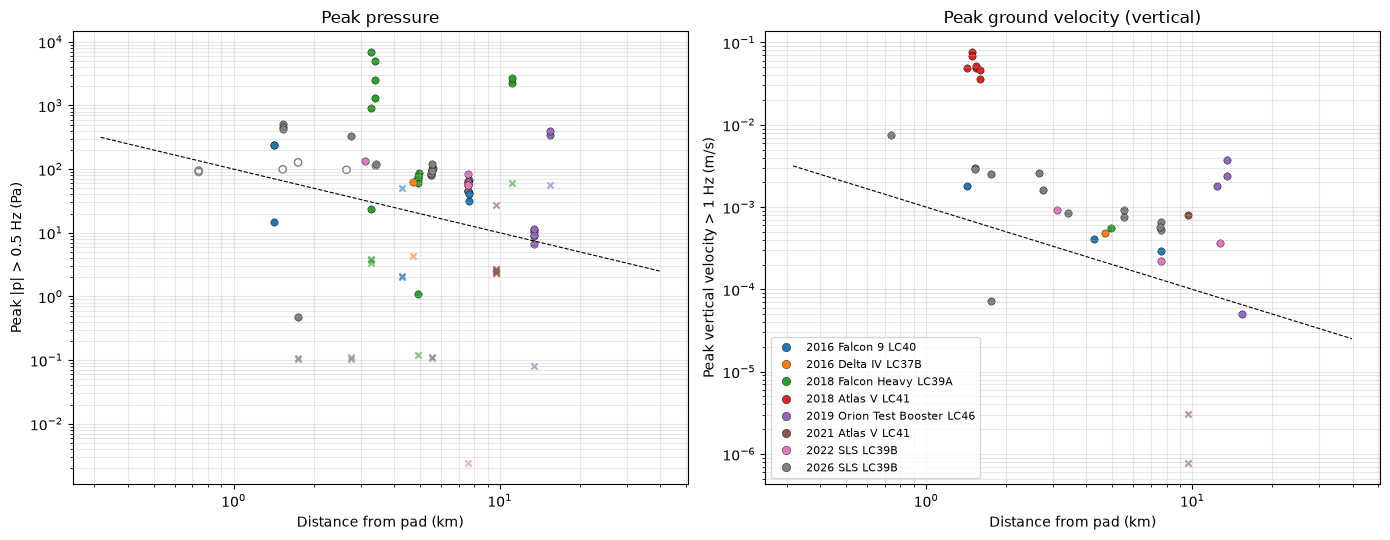

In [6]:
EVENT_COLORS = dict(zip(SUBSET, plt.cm.tab10(np.arange(len(SUBSET)) % 10)))
EVENT_LABELS = {e: f"{ev.origin_time.year} {sub.set_index('event_id').vehicle[e]} {ev.site_name}" for e, ev in events.items()}

def amp_plot(ax, kind, ylabel, ref):
    d = peaks[(peaks.kind == kind) & peaks.distance_km.notna()]
    for eid, g in d.groupby("event_id"):
        c = EVENT_COLORS[eid]
        ok = (g.snr >= 3) & ~g.lower_bound
        ax.scatter(g.distance_km[ok], g.peak[ok], color=c, s=28, edgecolor="k", lw=0.3)
        ax.scatter(g.distance_km[g.lower_bound], g.peak[g.lower_bound], facecolor="none", edgecolor=c, s=28)
        bad = (g.snr < 3) & ~g.lower_bound
        ax.scatter(g.distance_km[bad], g.peak[bad], color=c, marker="x", s=20, alpha=0.6)
    r = np.logspace(-0.5, 1.6, 50)
    ax.plot(r, ref / r, "k--", lw=0.8)
    ax.set(xscale="log", yscale="log", xlabel="Distance from pad (km)", ylabel=ylabel)
    ax.grid(alpha=0.3, which="both")

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
amp_plot(ax[0], "pressure", "Peak |p| > 0.5 Hz (Pa)", 100.0)
amp_plot(ax[1], "seismic_Z", "Peak vertical velocity > 1 Hz (m/s)", 1e-3)
handles = [plt.Line2D([], [], marker="o", ls="", color=EVENT_COLORS[e], mec="k", mew=0.3, label=EVENT_LABELS[e])
           for e in SUBSET if e in events]
ax[1].legend(handles=handles, fontsize=8, loc="lower left")
ax[0].set_title("Peak pressure"); ax[1].set_title("Peak ground velocity (vertical)")
fig.tight_layout()
fig.savefig(OUT / "subset_peaks_vs_distance.png", dpi=200)

## 6. Distance-reduced pressure by launch

Peak pressure × distance (Pa·km), per launch, from channels with SNR ≥ 3 that are not lower bounds.
For a point source with spherical spreading this is a crude source-strength measure; it ignores
directivity, the moving source (Artemis II notebook 40) and atmospheric refraction.

In [7]:
good = peaks[(peaks.kind == "pressure") & (peaks.snr >= 3) & ~peaks.lower_bound].copy()
good["reduced_Pa_km"] = good.peak * good.distance_km
summary = good.groupby(["event_id", "vehicle", "pad"]).agg(
    n_channels=("seed_id", "size"), r_min_km=("distance_km", "min"), r_max_km=("distance_km", "max"),
    median_reduced_Pa_km=("reduced_Pa_km", "median"), max_peak_Pa=("peak", "max")).reset_index()
summary["year"] = [events[e].origin_time.year for e in summary.event_id]
summary = summary.sort_values("year")
summary.to_csv(OUT / "subset_reduced_pressure.csv", index=False)
summary

,event_id,vehicle,pad,n_channels,r_min_km,r_max_km,median_reduced_Pa_km,max_peak_Pa,year
1,ksc-4d8977e0556d,Falcon 9,LC40,6,1.421331,7.635650,325.955634,239.256759,2016
3,ksc-84ff2d3935e5,Delta IV,LC37B,1,4.712826,4.712826,294.150925,62.414974,2016
2,ksc-63e156ef62c2,Falcon Heavy,LC39A,14,3.280881,11.086984,1697.813136,6940.796895,2018
5,ksc-da8b52e60732,Orion Test Booster,LC46,8,13.460525,15.413826,144.637563,395.754541,2019
4,ksc-893bace1e8c8,SLS,LC39B,7,3.103106,7.607696,462.516004,133.869176,2022
0,artemis2-20260401,SLS,LC39B,19,1.528376,7.632534,500.447719,511.657484,2026


## 7. Co-located infrasound channels

Many 2016–2022 sites had two or three infraBSU channels on one Centaur. Their peaks should agree
within a few tens of percent; larger ratios point to wrong sensitivities in `KSC.xml` (e.g. a
40 Vpp vs 1 Vpp gain setting, a factor of 40) or dead/wind-dominated sensors. This is the check
the 2016 relative-calibration notebook (`event_catalog_workflow_v5/04_event_catalog/30_...`) makes in
more detail.

In [8]:
p = peaks[peaks.kind == "pressure"]
rows = []
for (eid, sta), g in p.groupby(["event_id", "station"]):
    if len(g) < 2:
        continue
    ref = g.peak.median()
    for _, r in g.iterrows():
        rows.append(dict(event_id=eid, station=sta, channel=r.channel, peak_Pa=r.peak, snr=r.snr,
                         ratio_to_station_median=r.peak / ref))
colocated = pd.DataFrame(rows)
colocated.to_csv(OUT / "subset_colocated_infrasound.csv", index=False)
colocated.style.format({"peak_Pa": "{:.3g}", "snr": "{:.1f}", "ratio_to_station_median": "{:.2f}"})

,event_id,station,channel,peak_Pa,snr,ratio_to_station_median
0,artemis2-20260401,B01,HDI,99.3,103.9,0.22
1,artemis2-20260401,B01,DD0,512,440.2,1.15
2,artemis2-20260401,B01,DD1,454,380.5,1.02
3,artemis2-20260401,B01,DD2,434,311.0,0.98
4,artemis2-20260401,B03,HDI,128,69.7,433.49
5,artemis2-20260401,B03,DD0,0.483,3.4,1.64
6,artemis2-20260401,B03,DD1,0.104,1.1,0.35
7,artemis2-20260401,B03,DD2,0.106,1.0,0.36
8,artemis2-20260401,B05,DD0,329,404.6,2978.66
9,artemis2-20260401,B05,DD1,0.11,1.1,1.00


## Findings from this subset (2026-11-23 run)

* **The bridge works across all three network configurations** (2016 Centaur campaign, 2018–2022
  campaigns with geophones and Raspberry Shakes, 2026 network): 8/8 launches read, corrected and measured.
* **Gem overflow (Artemis II):** 6 Gem channels flagged; their peaks (≈ 90–130 Pa) are lower bounds,
  e.g. B01 HDI ≈ 100 Pa beside B01 infraBSU ≈ 450–510 Pa.
* **`KSC.xml` infraBSU gain (18.4 vs 736 counts/Pa) is wrong for some epochs** — resolved for
  DVEL1/DVEL2/DVEL3/RBLAB in notebook 15 (they ran at 1 Vpp; `vpp` was blank in the master sheet and the
  StationXML builder defaulted it to 40). Where an 18.4 and a
  736 channel share a site they agree (BCHH1 DD2 vs BCHH2 DD4–9 for Falcon Heavy 2018 and AA-2 2019;
  BCHH4 HD2 vs BCHH2 HD4–9 for Artemis I), but DVEL1, DVEL2, RBLAB (2018) and DVEL3 (2019) come out
  ≈ 35–40× too high (e.g. 340–400 Pa at 15 km from AA-2 against ≈ 10 Pa at 13.5 km on BCHH2;
  up to 6.9 kPa at 3.3 km from Falcon Heavy), as if these Centaurs ran at 1 Vpp (736 counts/Pa).
* **Geophone (EH?) sensitivity also looks ≈ 40× too small:** AA-2 PGV on BHP1/FIREP/TANKP (2–4 mm/s at
  12–13 km) is ≈ 50× the co-located-distance Trillium at DVEL3 (0.05 mm/s at 15 km), and Atlas V
  AEHF-4 gives 4–8 cm/s at 1.5 km on BHP2–8 (Artemis II: ≈ 3 mm/s at 1.5 km).
* **2016 BCHH DD2** reads ≈ 16× low against DD1/DD3 on both SES-9 and Delta IV NROL-37 — a known,
  stable low gain (also seen for the AMOS-6 explosion and in the 2016 relative-calibration outputs); **FIRE DD1–3** (2016) show no signal.
* **Dead or unconnected pressure channels** (SNR ≈ 1, peaks ≈ 0.1 Pa): BCHH2 DD7 (2018), DD8 (2019),
  HD5 (2022), DVEL1 DD4–6 (2018), 2026 B03 DD0–2, B05 DD1–2, B29 DD1–2. A per-channel QC list
  (bad epochs) should live in the ensemble config.
* **Atlas V Lucy (2021):** infrasound at the RBLAB site (RB166/RB383 HD1–3, RB268 DDF) shows no signal at
  9.6 km while RB383 HHZ does (SNR 82) — check those channel mappings.
* `1R.UNK..HD1` (2026) has no coordinates: an unmapped Gem.

## Notes

* Origin times are the reconciled catalog times; many are only to the minute, so `t_peak_s` cannot
  yet be used for travel times. Event-time refinement (from the airwave at the nearest station, as
  done for New Glenn) is a prerequisite for moving-source analyses.
* Station sets for the 2026 era come from the `artemis2` sheet; other 2026 campaigns need their own
  sheets or the `SDS2026_metadata` DOY ranges.